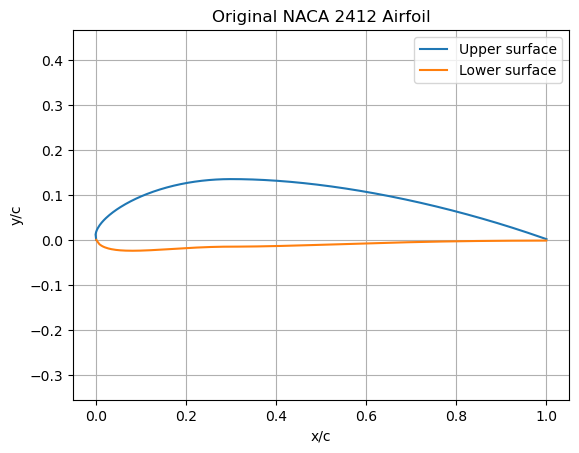

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def naca4(m, p, t, x):

    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1015*x**4
    )

    yc = np.where(
        x <= p,
        m/p**2 * (2*p*x - x**2),
        m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2)
    )

    dyc = np.where(
        x <= p,
        2*m/p**2 * (p-x),
        2*m/(1-p)**2 * (p-x)
    )

    theta = np.arctan(dyc)

    xu = x - yt*np.sin(theta)
    yu = yc + yt*np.cos(theta)

    xl = x + yt*np.sin(theta)
    yl = yc - yt*np.cos(theta)

    return xu, yu, xl, yl

# Generate random NACA four-digit parameters
rng = np.random.default_rng()

camber_digit = rng.integers(1, 10)
location_digit = rng.integers(1, 10)
thickness_digit = rng.integers(6, 19)

# Convert the digits into parameters
m = camber_digit / 100
p = location_digit / 10
t = thickness_digit / 100

# Generate the original airfoil
x = np.linspace(0, 1, 350)
xu, yu, xl, yl = naca4(m, p, t, x)

# Plot the original airfoil
plt.plot(xu, yu, label="Upper surface")
plt.plot(xl, yl, label="Lower surface")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Original NACA 2412 Airfoil")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


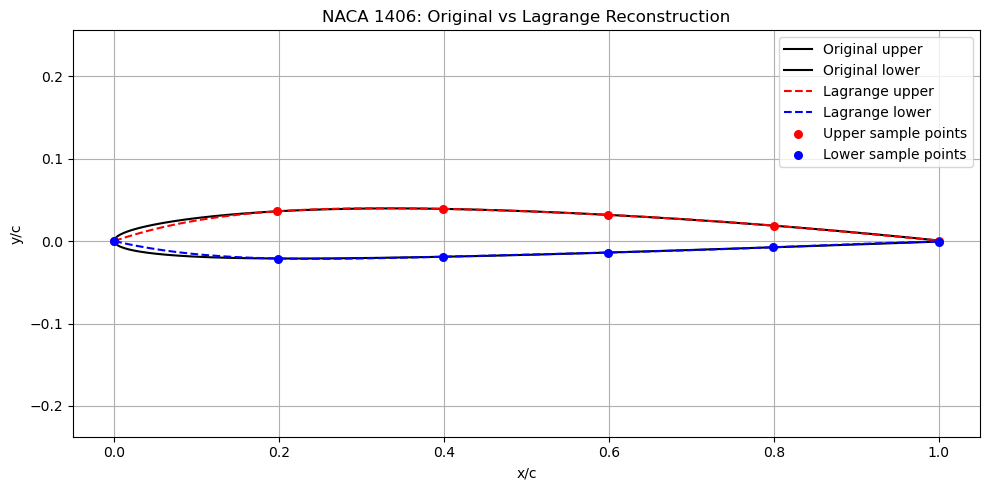


NACA Airfoil: 1406

UPPER SURFACE
Maximum absolute error: 0.0063684966941674
RMS error: 0.00167474455835433

LOWER SURFACE
Maximum absolute error: 0.0064042570226386
RMS error: 0.00170773246041791

COMBINED AIRFOIL
Maximum absolute error: 0.0064042570226386
RMS error: 0.00169131893682156


In [ ]:

#  LAGRANGE INTERPOLATION FUNCTION


def Lagrng(x, y, n, z):

    total = 0.0

    for i in range(n):

        product = y[i]

        for j in range(n):

            if i != j:
                product = product * (
                    (z - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total



# RECONSTRUCT AIRFOIL USING LAGRANGE INTERPOLATION


x_fine = np.linspace(x_sample[0], x_sample[-1], 400)
n = len(x_sample)

xu_rec = []
yu_rec = []
xl_rec = []
yl_rec = []

for z in x_fine:

    xu_rec.append(Lagrng(x_sample, xu_s, n, z))
    yu_rec.append(Lagrng(x_sample, yu_s, n, z))

    xl_rec.append(Lagrng(x_sample, xl_s, n, z))
    yl_rec.append(Lagrng(x_sample, yl_s, n, z))

xu_rec = np.array(xu_rec)
yu_rec = np.array(yu_rec)

xl_rec = np.array(xl_rec)
yl_rec = np.array(yl_rec)



# PLOT ORIGINAL AND LAGRANGE RECONSTRUCTION


plt.figure(figsize=(10, 5))

plt.plot(xu, yu, "k-", label="Original upper")
plt.plot(xl, yl, "k-", label="Original lower")

plt.plot(xu_rec, yu_rec, "r--", label="Lagrange upper")
plt.plot(xl_rec, yl_rec, "b--", label="Lagrange lower")

plt.scatter(
    xu_s, yu_s, color="red", s=30,
    label="Upper sample points", zorder=3
)

plt.scatter(
    xl_s, yl_s, color="blue", s=30,
    label="Lower sample points", zorder=3
)

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Lagrange Reconstruction")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



#  CALCULATE LAGRANGE RECONSTRUCTION ERRORS


# Reference values at the same chordwise coordinates.
# np.interp estimates original y-values from the 400-point data.

yu_reference = np.interp(x_fine, x, yu)
yl_reference = np.interp(x_fine, x, yl)

# Vertical errors
error_upper = yu_reference - yu_rec
error_lower = yl_reference - yl_rec

# Maximum absolute errors
max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

# Root mean square errors
rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

# Combined upper and lower surface errors
all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))



#  PRINT ERROR RESULTS


print(f"\nNACA Airfoil: {naca_name}")

print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper:.16f}")
print(f"RMS error: {rms_upper:.17f}")

print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower:.16f}")
print(f"RMS error: {rms_lower:.17f}")

print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined:.16f}")
print(f"RMS error: {rms_combined:.17f}")


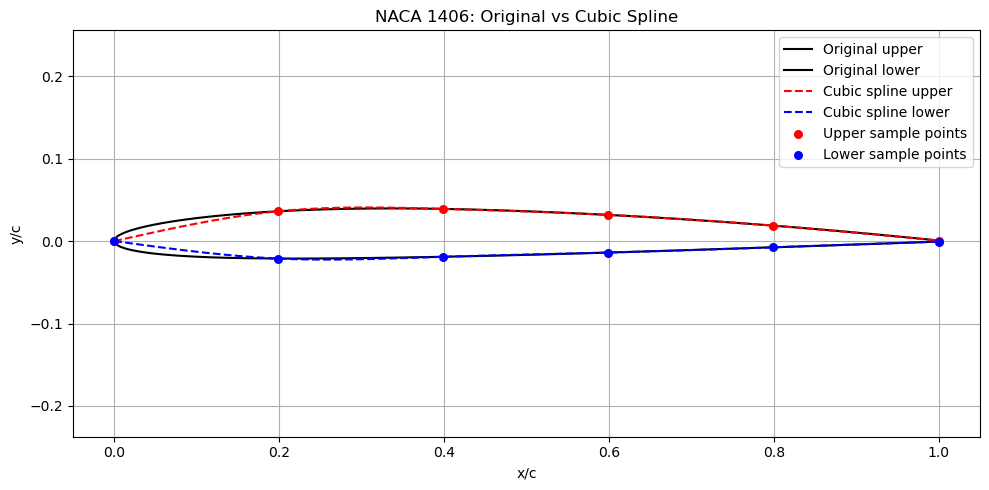


NACA Airfoil: 1406

UPPER SURFACE
Maximum absolute error: 0.0091489902764940
RMS error: 0.00281689682612082

LOWER SURFACE
Maximum absolute error: 0.0087801188601739
RMS error: 0.00268753652310552

COMBINED AIRFOIL
Maximum absolute error: 0.0091489902764940
RMS error: 0.00275297659743374


In [ ]:




#  NATURAL CUBIC SPLINE: CALCULATE SECOND DERIVATIVES


def calculate_spline_derivatives(x_data, y_data):

    n = len(x_data)

    if n < 3:
        raise ValueError("At least 3 sample points are required.")

    if len(y_data) != n:
        raise ValueError("x_data and y_data must have equal lengths.")

    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

    h = np.diff(x_data)

    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2)

    for i in range(1, n - 1):

        row = i - 1

        b[row] = 6 * (
            (y_data[i + 1] - y_data[i]) / h[i]
            - (y_data[i] - y_data[i - 1]) / h[i - 1]
        )

        A[row, row] = 2 * (h[i - 1] + h[i])

        if i > 1:
            A[row, row - 1] = h[i - 1]

        if i < n - 2:
            A[row, row + 1] = h[i]

    M_inner = np.linalg.solve(A, b)

    # Natural spline boundary conditions
    M = np.zeros(n)
    M[1:-1] = M_inner

    return h, M


# Calculate upper and lower surface derivatives
h_upper, M_upper = calculate_spline_derivatives(x_sample, yu_s)
h_lower, M_lower = calculate_spline_derivatives(x_sample, yl_s)


#  CUBIC SPLINE: EVALUATE ONE QUERY POINT


def cubic_spline_value(x_data, y_data, h, M, xq):

    if xq < x_data[0] or xq > x_data[-1]:
        raise ValueError("Query point is outside the sample range.")

    i = np.searchsorted(x_data, xq) - 1
    i = max(0, min(i, len(x_data) - 2))

    term1 = (
        M[i] * (x_data[i + 1] - xq)**3
        / (6 * h[i])
    )

    term2 = (
        M[i + 1] * (xq - x_data[i])**3
        / (6 * h[i])
    )

    term3 = (
        (y_data[i] - M[i] * h[i]**2 / 6)
        * (x_data[i + 1] - xq) / h[i]
    )

    term4 = (
        (y_data[i + 1] - M[i + 1] * h[i]**2 / 6)
        * (xq - x_data[i]) / h[i]
    )

    return term1 + term2 + term3 + term4


#  RECONSTRUCT BOTH SURFACES


x_fine = np.linspace(x_sample[0], x_sample[-1], 400)

yu_spline = np.array([
    cubic_spline_value(x_sample, yu_s, h_upper, M_upper, z)
    for z in x_fine
])

yl_spline = np.array([
    cubic_spline_value(x_sample, yl_s, h_lower, M_lower, z)
    for z in x_fine
])


#  PLOT ORIGINAL AND CUBIC SPLINE AIRFOILS


# The spline interpolates y as a function of chordwise x.
# Use x_fine as the x-coordinate for the reconstructed curves.

plt.figure(figsize=(10, 5))

plt.plot(xu, yu, "k-", label="Original upper")
plt.plot(xl, yl, "k-", label="Original lower")

plt.plot(x_fine, yu_spline, "r--", label="Cubic spline upper")
plt.plot(x_fine, yl_spline, "b--", label="Cubic spline lower")

plt.scatter(x_sample, yu_s, color="red", s=30,
            label="Upper sample points", zorder=3)
plt.scatter(x_sample, yl_s, color="blue", s=30,
            label="Lower sample points", zorder=3)

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Cubic Spline")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


#  CALCULATE ERRORS


# Compare spline y-values with the original surface y-values
# at exactly the same chordwise query coordinates.

yu_reference = np.interp(x_fine, x, yu)
yl_reference = np.interp(x_fine, x, yl)

error_upper = yu_reference - yu_spline
error_lower = yl_reference - yl_spline

# Maximum absolute vertical error
max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

# Root mean square vertical error
rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

# Combined upper and lower surface errors
all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))



# PRINT ERROR RESULTS


print(f"\nNACA Airfoil: {naca_name}")

print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper:.16f}")
print(f"RMS error: {rms_upper:.17f}")

print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower:.16f}")
print(f"RMS error: {rms_lower:.17f}")

print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined:.16f}")
print(f"RMS error: {rms_combined:.17f}")
